# 2. EDA and features

What the application table looks like and how `src/features.py` cleans it. The same function is used for training and serving.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

METRICS = json.loads((ROOT / "reports" / "metrics.json").read_text())
SOURCE = METRICS["meta"]["data_source"]
display(Markdown(
    "> **Data source: real Home Credit data.**" if METRICS["meta"]["resume_safe"]
    else "> ⚠️ **SYNTHETIC DATA. Plumbing check only; do not read these numbers as findings.**"))

def load_application():
    """Real CSV if present and the reports came from it, otherwise the synthetic stand-in."""
    from src import synthetic
    path = ROOT / "data" / "application_train.csv"
    if METRICS["meta"]["resume_safe"] and path.exists():
        from src.pipeline import APP_COLUMNS
        return pd.read_csv(path, usecols=APP_COLUMNS)
    return synthetic.make_application_train(n=METRICS["meta"]["n_rows"], seed=METRICS["meta"]["seed"])


> **Data source: real Home Credit data.**

In [2]:
from src.features import FEATURE_COLUMNS, build_features
from src.validation import validate_training_frame
app = load_application()
report = validate_training_frame(app)
print(f"{report['n_rows']:,} rows, default rate {report['default_rate']:.2%}")
pd.Series(report["missing_rate"]).sort_values(ascending=False).to_frame("missing share")

307,511 rows, default rate 8.07%


,missing share
EXT_SOURCE_1,0.5638
EXT_SOURCE_3,0.1983
EXT_SOURCE_2,0.0021
AMT_GOODS_PRICE,0.0009
AMT_INCOME_TOTAL,0.0000
AMT_CREDIT,0.0000
AMT_ANNUITY,0.0000
DAYS_BIRTH,0.0000
DAYS_EMPLOYED,0.0000


## Data quirks handled

- `DAYS_BIRTH` is negative days. `DAYS_EMPLOYED == 365243` is a placeholder for *not employed* and is treated as **missing**, not as 1,000 years of work.

In [3]:
print("DAYS_EMPLOYED placeholder share:", report["employed_placeholder_share"])
feats = build_features(app); y = app.TARGET.values
feats["TARGET"] = y
feats[["AGE_YEARS", "YEARS_EMPLOYED", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "EXT_SOURCE_MEAN"]].describe().T

DAYS_EMPLOYED placeholder share: 0.1801


,count,mean,std,min,25%,50%,75%,max
AGE_YEARS,307511.0,43.906900,11.947950,20.503765,33.984942,43.121150,53.886379,69.073238
YEARS_EMPLOYED,252137.0,6.527500,6.402081,-0.000000,2.099932,4.511978,8.692676,49.040383
CREDIT_INCOME_RATIO,307511.0,3.957570,2.689728,0.004808,2.018667,3.265067,5.159880,84.736842
ANNUITY_INCOME_RATIO,307499.0,0.180930,0.094574,0.000224,0.114782,0.162833,0.229067,1.875965
EXT_SOURCE_MEAN,307339.0,0.509251,0.149802,0.000006,0.413648,0.524502,0.622819,0.878903


## Which features separate defaulters?

In [4]:
from sklearn.metrics import roc_auc_score
rows = []
for c in FEATURE_COLUMNS:
    m = feats[c].notna()
    a = roc_auc_score(y[m], feats.loc[m, c]) if m.sum() > 100 else np.nan
    rows.append({"feature": c, "single-feature AUC": round(max(a, 1 - a), 3), "missing %": round(100 * (~m).mean(), 1)})
pd.DataFrame(rows).sort_values("single-feature AUC", ascending=False)

,feature,single-feature AUC,missing %
12,EXT_SOURCE_MEAN,0.717,0.1
11,EXT_SOURCE_3,0.679,19.8
9,EXT_SOURCE_1,0.666,56.4
10,EXT_SOURCE_2,0.656,0.2
0,AGE_YEARS,0.583,0.0
1,YEARS_EMPLOYED,0.582,18.0
7,CREDIT_GOODS_RATIO,0.569,0.1
8,CREDIT_TERM,0.532,0.0
6,ANNUITY_INCOME_RATIO,0.520,0.0
2,AMT_INCOME_TOTAL,0.519,0.0


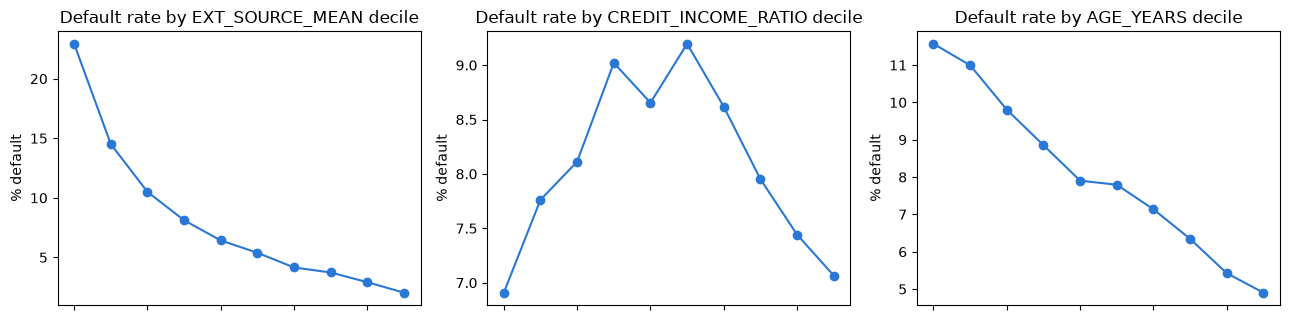

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, c in zip(axes, ["EXT_SOURCE_MEAN", "CREDIT_INCOME_RATIO", "AGE_YEARS"]):
    q = pd.qcut(feats[c], 10, duplicates="drop")
    (feats.groupby(q, observed=True).TARGET.mean() * 100).plot(ax=ax, marker="o", color="#2a78d6")
    ax.set_title(f"Default rate by {c} decile"); ax.set_xlabel(""); ax.set_xticklabels([]); ax.set_ylabel("% default")
plt.tight_layout(); plt.show()

## Why gender is not a feature

`CODE_GENDER` stays out of the model on purpose and is used only for the fairness audit. Excluding it does not guarantee equal outcomes (other features can act as proxies), which is why notebook 04 measures the gap.